# Ejercicio Regression Tree
Son datos de temperaturas tomados de la ciudad de Seattle. El objetivo es intentar predecir lo mejor posible la máxima temperatura (columna `actual`) que alcanzaremos al día siguiente. Para ello contaremos con temperaturas de los dos días anteriores, históricos de máximas temperaturas y un amigo bastante chapas que te da su predicción del tiempo cada día.

**Resumen de datos**:
* year: 2016 for all data points
* month: number for month of the year
* day: number for day of the year
* week: day of the week as a character string
* temp_2: max temperature 2 days prior
* temp_1: max temperature 1 day prior
* average: historical average max temperature
* actual: max temperature measurement
* friend: your friend’s prediction, a random number between 20 below the average and 20 above the average


### 1. Importa el csv "temps.csv"

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('data/temps.csv')

In [3]:
df.head()

,year,month,day,week,temp_2,temp_1,average,actual,friend
0,2016,1,1,Fri,45,45,45.6,45,29
1,2016,1,2,Sat,44,45,45.7,44,61
2,2016,1,3,Sun,45,44,45.8,41,56
3,2016,1,4,Mon,44,41,45.9,40,53
4,2016,1,5,Tues,41,40,46.0,44,41


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 348 entries, 0 to 347
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   year     348 non-null    int64  
 1   month    348 non-null    int64  
 2   day      348 non-null    int64  
 3   week     348 non-null    str    
 4   temp_2   348 non-null    int64  
 5   temp_1   348 non-null    int64  
 6   average  348 non-null    float64
 7   actual   348 non-null    int64  
 8   friend   348 non-null    int64  
dtypes: float64(1), int64(7), str(1)
memory usage: 24.6 KB


In [5]:
#NOTA: El día de la semana está como str, la lógica me invita a pensar que no influye en la temperatura por lo que paso de él y no lo convierto a float o int.

In [6]:
df.describe()

,year,month,day,temp_2,temp_1,average,actual,friend
count,348.0,348.000000,348.000000,348.000000,348.000000,348.000000,348.000000,348.000000
mean,2016.0,6.477011,15.514368,62.652299,62.701149,59.760632,62.543103,60.034483
std,0.0,3.498380,8.772982,12.165398,12.120542,10.527306,11.794146,15.626179
min,2016.0,1.000000,1.000000,35.000000,35.000000,45.100000,35.000000,28.000000
25%,2016.0,3.000000,8.000000,54.000000,54.000000,49.975000,54.000000,47.750000
50%,2016.0,6.000000,15.000000,62.500000,62.500000,58.200000,62.500000,60.000000
75%,2016.0,10.000000,23.000000,71.000000,71.000000,69.025000,71.000000,71.000000
max,2016.0,12.000000,31.000000,117.000000,117.000000,77.400000,92.000000,95.000000


In [7]:
#Veo arriba que 'year' es un valor cte igual a 2016 por lo que me puedo cargar esa columna.
df = df.drop(columns=['year'])

### 2. Realiza un análisis exploratorio junto con un Feature Engineering

In [8]:
import seaborn as sns

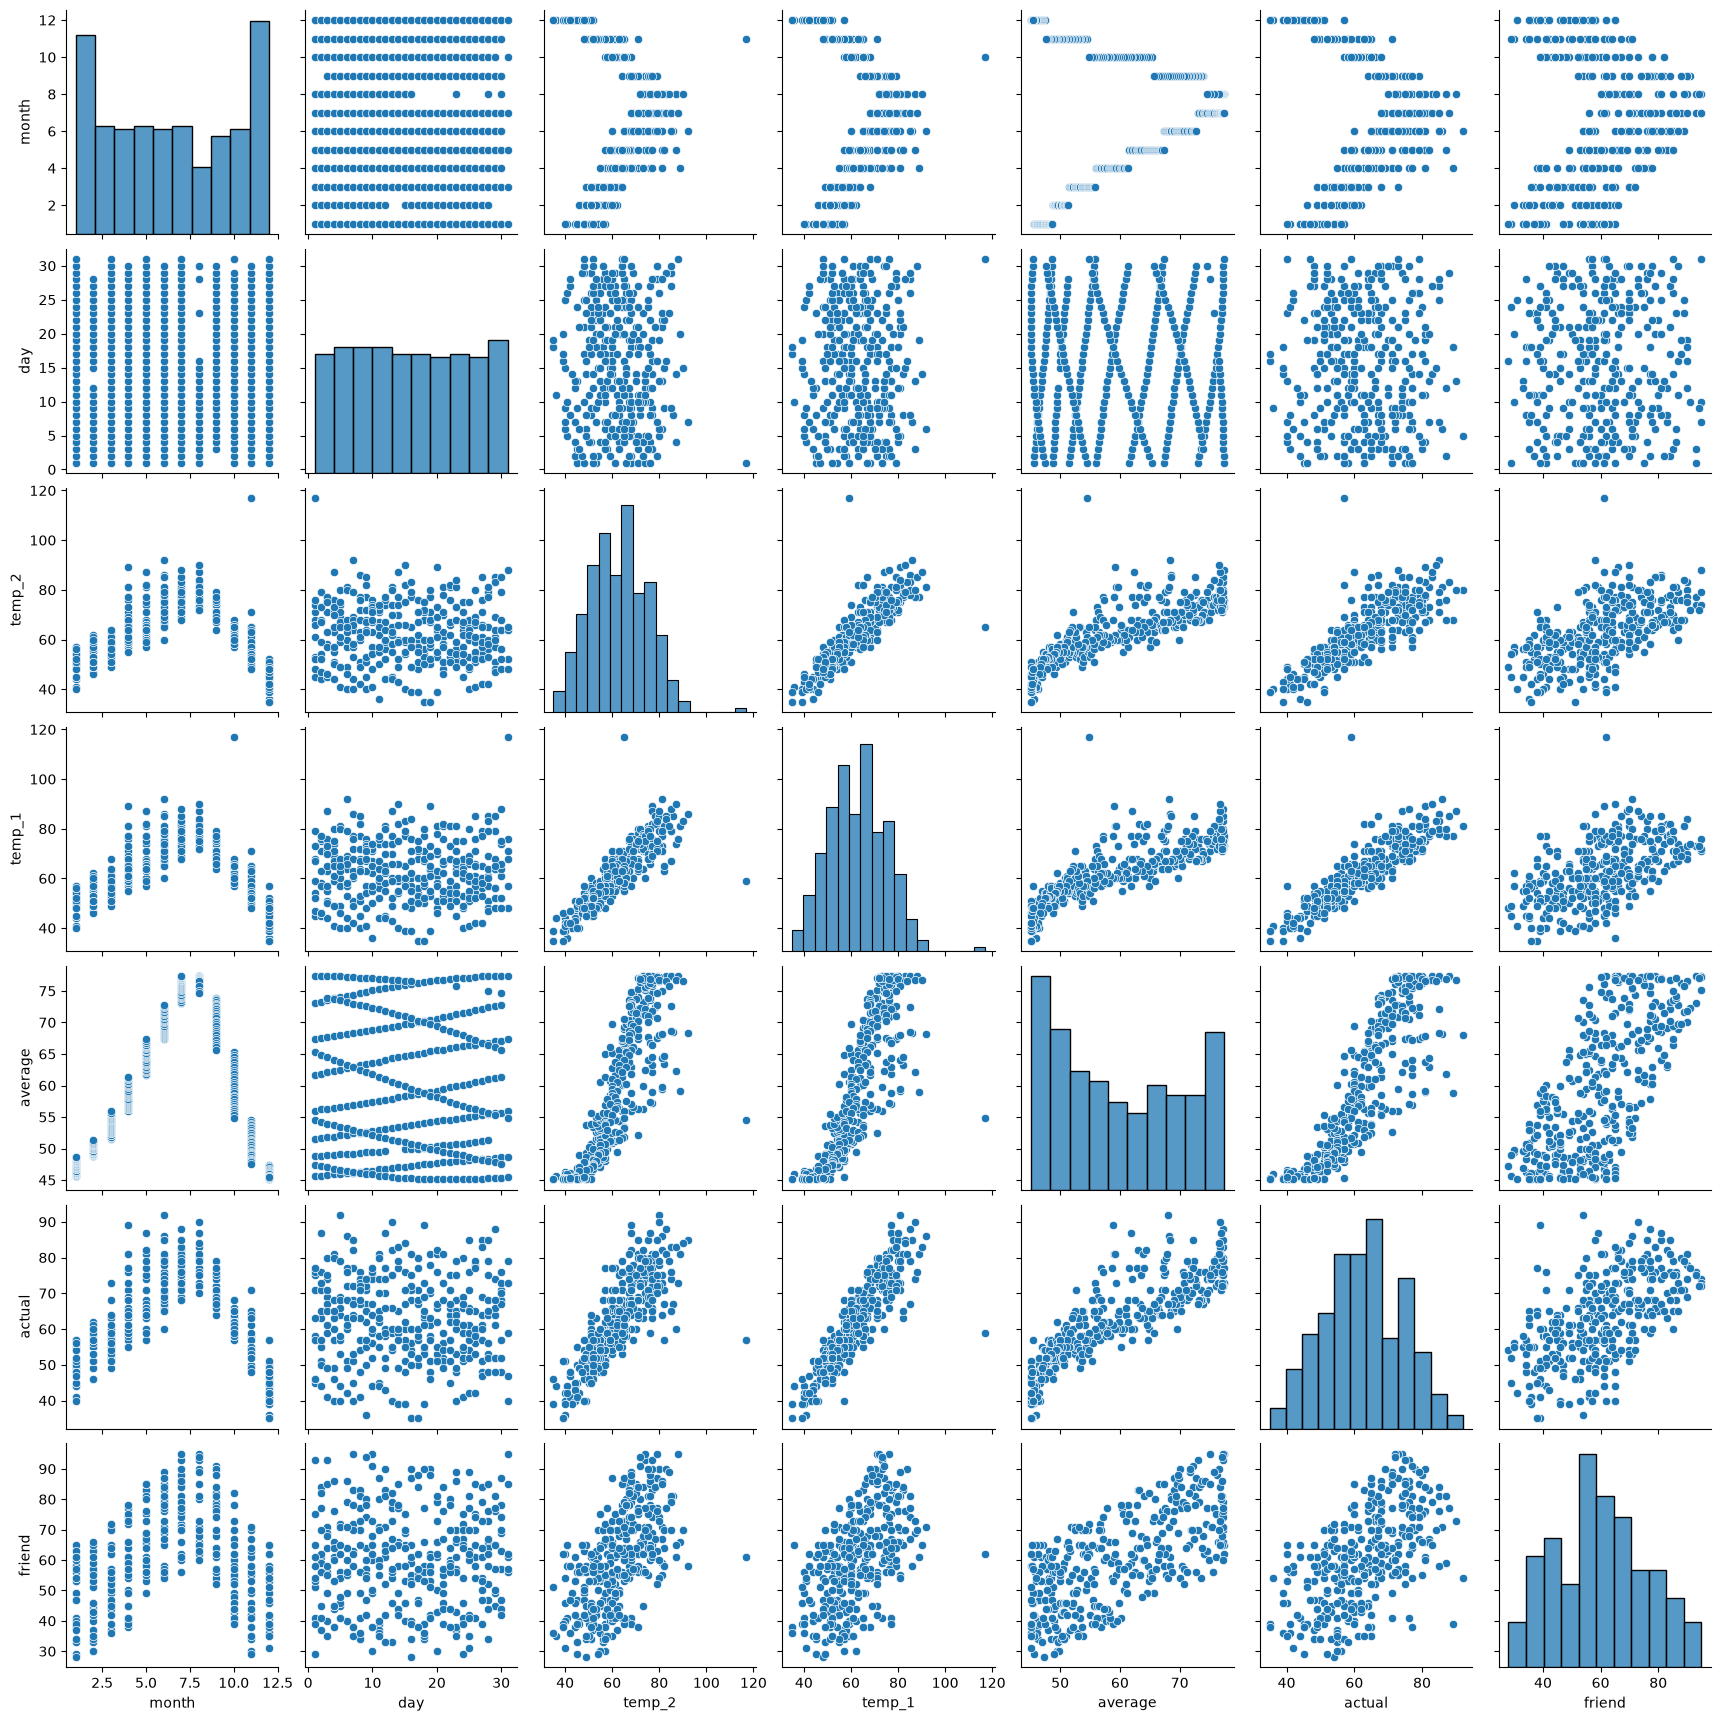

In [9]:
sns.pairplot(df);

In [10]:
#Intuyo que la y ('actual'), parece estar bien relacionada con las X: 'temp_2', 'temp_1', 'average' y 'friend'.

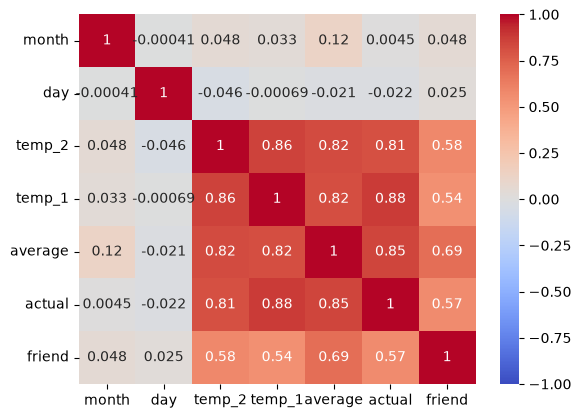

In [11]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", vmin=-1);

In [12]:
#Confirmadas las sospechas

### 3. Selecciona variables y divide en train y test

In [13]:
X = df[['temp_2','temp_1','average','friend']]  #Me quedo con las vbles más correlacionadas
y = df['actual']

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)  #Divido 80% train y 20% test

### 4. Entrena el modelo


In [15]:
from sklearn.tree import DecisionTreeRegressor  #árbol regresor porque estoy prediciendo números con rel. no lineales complejas

m_depth2 = DecisionTreeRegressor(max_depth=2, random_state=42)   #Creo el modelo profundidad 2, y semilla 42
m_depth2.fit(X_train, y_train)   #Entreno al modelo (con el 80% de los datos). Celda anterior

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

### 5. Evaluación de tu modelo
Calcula el coeficiente de determinación. 

Calcula el MAE, MAPE, MSE y RMSE.

In [16]:
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error, mean_squared_error

y_pred_2 = m_depth2.predict(X_test)

r2_2 = r2_score(y_test, y_pred_2)
mae_2 = mean_absolute_error(y_test, y_pred_2)
mape_2 = mean_absolute_percentage_error(y_test, y_pred_2)
mse_2 = mean_squared_error(y_test, y_pred_2)
rmse_2 = np.sqrt(mse_2)

print("--- MÉTRICAS TEST ---")
print(f"R2 (Coeficiente de determinación): {r2_2:.4f}")
print(f"MAE: {mae_2:.4f}")
print(f"MAPE: {mape_2:.4f}")
print(f"MSE: {mse_2:.4f}")
print(f"RMSE: {rmse_2:.4f}")

--- MÉTRICAS TEST ---
R2 (Coeficiente de determinación): 0.7308
MAE: 4.8888
MAPE: 0.0774
MSE: 37.6479
RMSE: 6.1358


In [17]:
y_pred_train_2 = m_depth2.predict(X_train)

r2_train_2 = r2_score(y_train, y_pred_train_2)
mae_train_2 = mean_absolute_error(y_train, y_pred_train_2)
mape_train_2 = mean_absolute_percentage_error(y_train, y_pred_train_2)
mse_train_2 = mean_squared_error(y_train, y_pred_train_2)
rmse_train_2 = np.sqrt(mse_train_2)

print("--- MÉTRICAS TRAIN (Prof. 2)---")
print(f"R2 (Coeficiente de determinación): {r2_train_2:.4f}")
print(f"MAE: {mae_train_2:.4f}")
print(f"MAPE: {mape_train_2:.4f}")
print(f"MSE: {mse_train_2:.4f}")
print(f"RMSE: {rmse_train_2:.4f}")


--- MÉTRICAS TRAIN (Prof. 2)---
R2 (Coeficiente de determinación): 0.7929
MAE: 4.1920
MAPE: 0.0682
MSE: 28.6221
RMSE: 5.3500


In [18]:
#Veo que el R^2 en test y train son parecidos y sobre 0.8 por lo que no hay overfitting.
#Además veo que en test el error es ligeramente superior al de train.

### 6. Representa el árbol de decisión

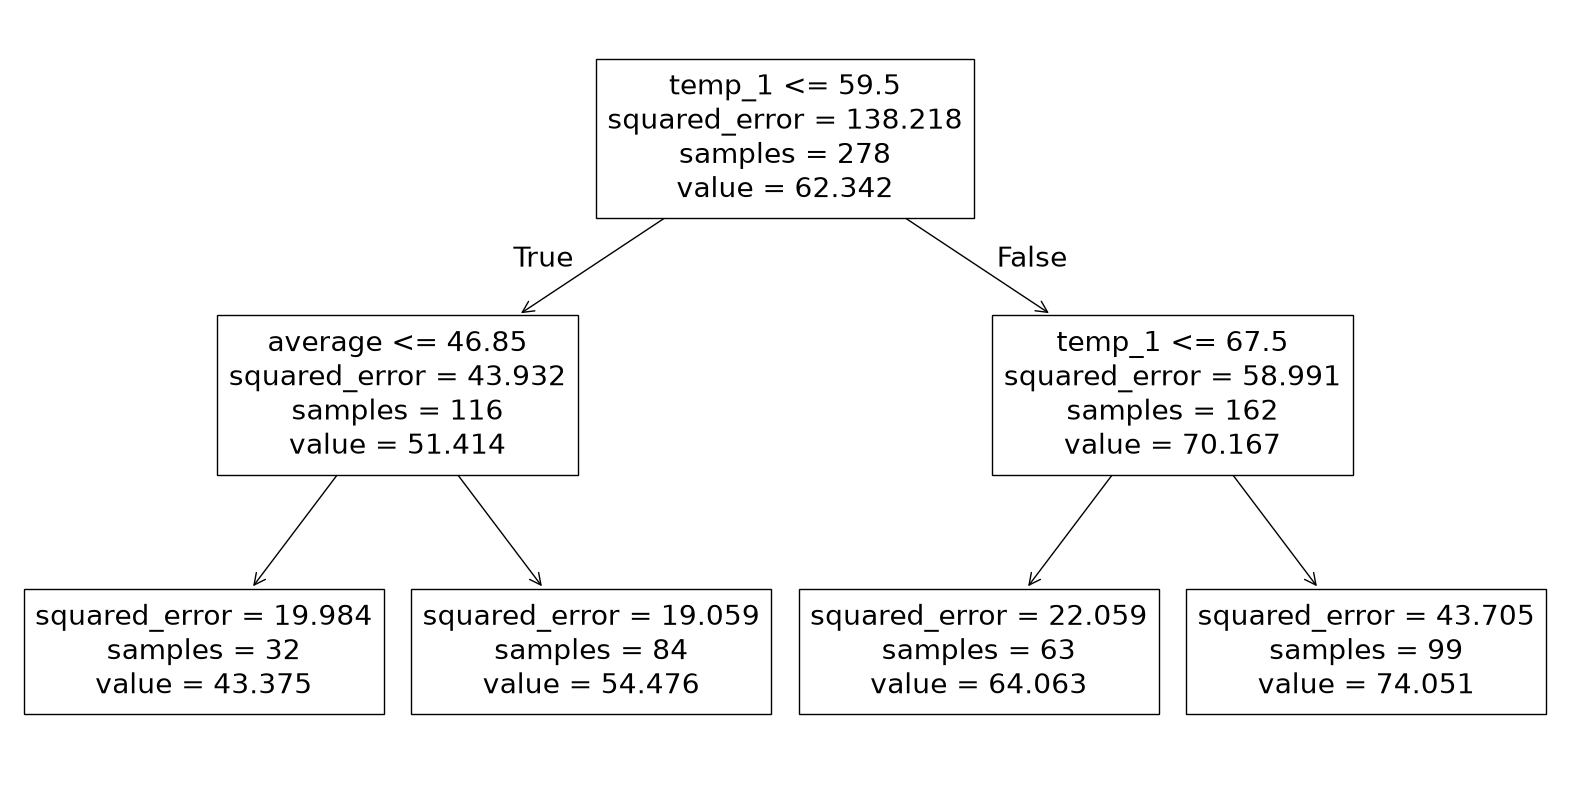

In [19]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(m_depth2, feature_names=X.columns)
plt.show()

### 7. Modifica el max_depth a 3 y vuelve a entrenarlo

In [20]:
m_depth3 = DecisionTreeRegressor(max_depth=3, random_state=42)   #Creo el modelo profundidad 3, y semilla 42
m_depth3.fit(X_train, y_train)   #Entreno

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

### 8. Vuelve a evaluar tu modelo

In [21]:
y_pred_3 = m_depth3.predict(X_test)

r2_3 = r2_score(y_test, y_pred_3)
mae_3 = mean_absolute_error(y_test, y_pred_3)
mape_3 = mean_absolute_percentage_error(y_test, y_pred_3)
mse_3 = mean_squared_error(y_test, y_pred_3)
rmse_3 = np.sqrt(mse_3)

print("--- MÉTRICAS TEST ---")
print(f"R2 (Coeficiente de determinación): {r2_3:.4f}")
print(f"MAE: {mae_3:.4f}")
print(f"MAPE: {mape_3:.4f}")
print(f"MSE: {mse_3:.4f}")
print(f"RMSE: {rmse_3:.4f}")

--- MÉTRICAS TEST ---
R2 (Coeficiente de determinación): 0.7787
MAE: 4.2672
MAPE: 0.0674
MSE: 30.9465
RMSE: 5.5630


In [22]:
y_pred_train_3 = m_depth3.predict(X_train)

r2_train_3 = r2_score(y_train, y_pred_train_3)
mae_train_3 = mean_absolute_error(y_train, y_pred_train_3)
mape_train_3 = mean_absolute_percentage_error(y_train, y_pred_train_3)
mse_train_3 = mean_squared_error(y_train, y_pred_train_3)
rmse_train_3 = np.sqrt(mse_train_3)

print("--- MÉTRICAS TRAIN (Prof. 3)---")
print(f"R2 (Coeficiente de determinación): {r2_train_3:.4f}")
print(f"MAE: {mae_train_3:.4f}")
print(f"MAPE: {mape_train_3:.4f}")
print(f"MSE: {mse_train_3:.4f}")
print(f"RMSE: {rmse_train_3:.4f}")

--- MÉTRICAS TRAIN (Prof. 3)---
R2 (Coeficiente de determinación): 0.8397
MAE: 3.6758
MAPE: 0.0587
MSE: 22.1500
RMSE: 4.7064


In [23]:
#Veo que el R^2 en test y train son parecidos y sobre 0.8 por lo que no hay overfitting.
#Además veo que en test el error es ligeramente superior al de train.

### 9. Vuelve a representar su árbol

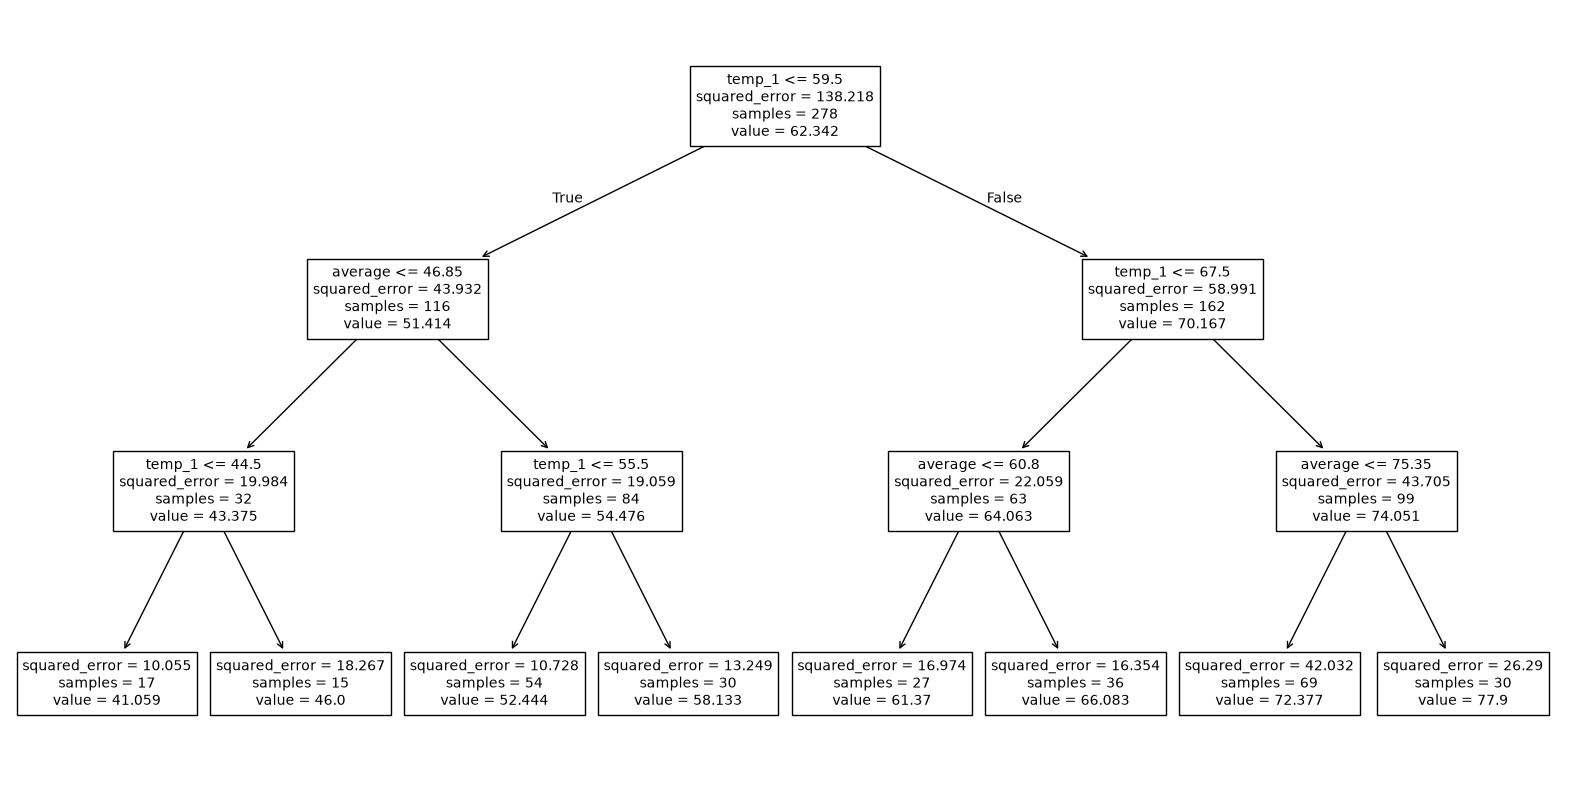

In [24]:
plt.figure(figsize=(20, 10))
plot_tree(m_depth3, feature_names=X.columns)
plt.show()

### 10. Utiliza un grid search con cross validation para hiperparametrizar tu modelo

In [25]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [2, 3, 4, 5, 6, None],   #None es sin límite
    'min_samples_split': list(range(2, 15, 2)),  #Empieza en 2: 2, 4, 6, 8, 10, 12, 14. Exijo un mínimo de datos para que la rama se divida en dos.
    'min_samples_leaf': list(range(1, 10))       #Este sí puede empezar en 1. Obligo a que cada hoja final tenga al menos entre 1 y 9 datos.
}                                                #6*7*9, tengo 378 combinaciones posibles.

grid_reg = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),   #semilla 42
    param_grid=param_grid,
    cv=5,   #Divido X_train en 5 trozos, e.d., entrena con 4 y evalua con 1. Rotando 5 veces por cada combinación.
    scoring='neg_mean_absolute_error',  #Scikit-learn siempre intenta maximizar. Como el error MAE queremos que sea lo menor posible lo paso a negativo.
    n_jobs=-1   #optimización computacional que no entiendo
)

grid_reg.fit(X_train, y_train)   #Arranco la búsqueda usando únicamente los datos de train

print("Mejores parámetros:", grid_reg.best_params_)   #Me muestra la combinación ganadora
mejor_modelo_reg = grid_reg.best_estimator_

#Evaluación del mejor modelo
y_pred_best = mejor_modelo_reg.predict(X_test)

r2_best = r2_score(y_test, y_pred_best)
mae_best = mean_absolute_error(y_test, y_pred_best)
mape_best = mean_absolute_percentage_error(y_test, y_pred_best)
mse_best = mean_squared_error(y_test, y_pred_best)
rmse_best = np.sqrt(mse_best)

print("--- MÉTRICAS TEST ---")
print(f"R2 (Coeficiente de determinación): {r2_best:.4f}")
print(f"MAE: {mae_best:.4f}")
print(f"MAPE: {mape_best:.4f}")
print(f"MSE: {mse_best:.4f}")
print(f"RMSE: {rmse_best:.4f}")


Mejores parámetros: {'max_depth': 4, 'min_samples_leaf': 6, 'min_samples_split': 14}
--- MÉTRICAS TEST ---
R2 (Coeficiente de determinación): 0.7938
MAE: 4.0218
MAPE: 0.0635
MSE: 28.8251
RMSE: 5.3689


In [26]:
y_pred_train_best = mejor_modelo_reg.predict(X_train)

r2_train_best = r2_score(y_train, y_pred_train_best)
mae_train_best = mean_absolute_error(y_train, y_pred_train_best)
mape_train_best = mean_absolute_percentage_error(y_train, y_pred_train_best)
mse_train_best = mean_squared_error(y_train, y_pred_train_best)
rmse_train_best = np.sqrt(mse_train_best)

print("--- MÉTRICAS TRAIN (MEJOR MODELO)---")
print(f"R2 (Coeficiente de determinación): {r2_train_best:.4f}")
print(f"MAE: {mae_train_best:.4f}")
print(f"MAPE: {mape_train_best:.4f}")
print(f"MSE: {mse_train_best:.4f}")
print(f"RMSE: {rmse_train_best:.4f}")

--- MÉTRICAS TRAIN (MEJOR MODELO)---
R2 (Coeficiente de determinación): 0.8670
MAE: 3.3494
MAPE: 0.0535
MSE: 18.3856
RMSE: 4.2878


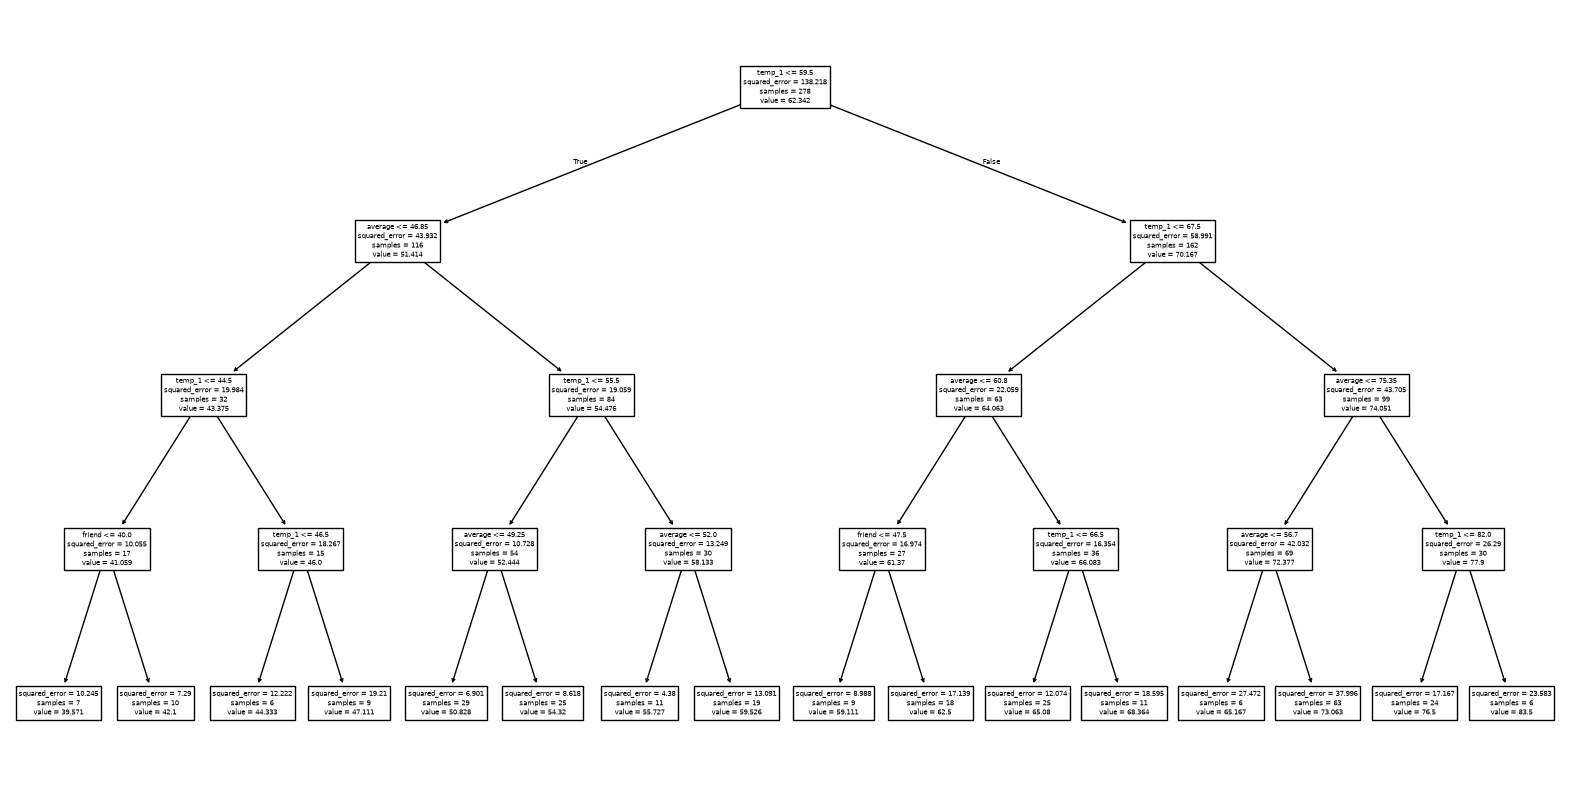

In [27]:
plt.figure(figsize=(20, 10))
plot_tree(mejor_modelo_reg, feature_names=X.columns)
plt.show()

In [28]:
modelos = {
    'Árbol max_depth=2': m_depth2,
    'Árbol max_depth=3': m_depth3,
    'GridSearch (max_depth=4)': mejor_modelo_reg
}

resultados = []

for nombre, mod in modelos.items():
    pred_train = mod.predict(X_train)
    pred_test = mod.predict(X_test)
    
    resultados.append({
        'Modelo': nombre,
        'R2 Train': round(r2_score(y_train, pred_train), 4),
        'R2 Test': round(r2_score(y_test, pred_test), 4),
        'MAE Train': round(mean_absolute_error(y_train, pred_train), 4),
        'MAE Test': round(mean_absolute_error(y_test, pred_test), 4),
        'RMSE Test': round(np.sqrt(mean_squared_error(y_test, pred_test)), 4)
    })

df_comparativa = pd.DataFrame(resultados)
display(df_comparativa)


,Modelo,R2 Train,R2 Test,MAE Train,MAE Test,RMSE Test
0,Árbol max_depth=2,0.7929,0.7308,4.1920,4.8888,6.1358
1,Árbol max_depth=3,0.8397,0.7787,3.6758,4.2672,5.5630
2,GridSearch (max_depth=4),0.8670,0.7938,3.3494,4.0218,5.3689


In [29]:
#Veo que en todos los caos el R^2 en test y train son parecidos y sobre 0.8 por lo que no hay overfitting.
#Además veo que en test el error es ligeramente superior al de train.
#También veo como con el mejor modelo obtengo los mejores resultados, mayor R^2 (si llegar a overfitting) y errores más pequeños.

### 11. Obten el `feature_importances` de cada variable en el último modelo

In [30]:
importancias = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': mejor_modelo_reg.feature_importances_   #Atributo que obtienes los coef que miden cuánto ayudó cada variable a reducir el error al dividir las ramas.
}).sort_values(by='Importancia', ascending=False)

print(importancias)

  Variable  Importancia
1   temp_1     0.863797
2  average     0.133345
3   friend     0.002859
0   temp_2     0.000000


In [31]:
#Se demuestra matemáticamente lo que decía el enunciado: friend es ruido aleatorio (importancia 0.0028) y temp_1 es la variable dominante (0.8638).

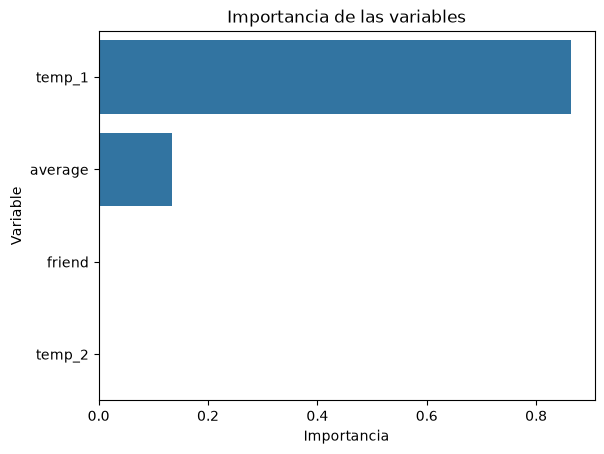

In [32]:
#Muestro con un gráfico de barras
sns.barplot(data=importancias, x='Importancia', y='Variable')
plt.title('Importancia de las variables')
plt.show()


### 12. Construye un nuevo modelo `DecisionTreeClassifier` que te clasifique cuando en un día va a hacer una temperatura mayor a 15ºC (59ºF). ¡Deberá tratarse como un problema de **clasificación**! Utiliza un grid search con cross validation y evalúa el mejor modelo.

In [33]:
#En este apartado el problema cambia radicalmente: pasamos de Regresión (predecir un número continuo, ej. 62.5 ºF) 
#a Clasificación Binaria (predecir una categoría: ¿Hará más de 59 ºF? Sí o No).

In [34]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

#Creo la variable objetivo binaria (1 si > 59°F (True), 0 si <= 59°F (False))
y_clf = (df['actual'] > 59).astype(int)

#Vuelvo a dividir train/test
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_clf, test_size=0.2, random_state=42)

#Grid Search con Cross Validation
param_grid = {
    'max_depth': [2, 3, 4, 5, 6, None],           #Sigo mismo criterio que antes
    'min_samples_split': list(range(2, 15, 2)), 
    'min_samples_leaf': list(range(1, 10))       
}

grid_clf = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',   #Optimizo por accuracy (% de existos), en lugar del menor error como antes
    n_jobs=-1
)

grid_clf.fit(X_train_c, y_train_c)   #Entreno


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 4, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=

In [35]:
#Evaluo
print("Mejores parámetros clasificación:", grid_clf.best_params_)
mejor_modelo_clf = grid_clf.best_estimator_
y_pred_c = mejor_modelo_clf.predict(X_test_c)

print("--- MÉTRICAS TEST ---")
print(f"Accuracy en test: {accuracy_score(y_test_c, y_pred_c):.4f}\n")
print("Matriz de confusión:\n", confusion_matrix(y_test_c, y_pred_c))
print("\nReporte de clasificación:\n", classification_report(y_test_c, y_pred_c))

Mejores parámetros clasificación: {'max_depth': 3, 'min_samples_leaf': 6, 'min_samples_split': 2}
--- MÉTRICAS TEST ---
Accuracy en test: 0.9143

Matriz de confusión:
 [[23  5]
 [ 1 41]]

Reporte de clasificación:
               precision    recall  f1-score   support

           0       0.96      0.82      0.88        28
           1       0.89      0.98      0.93        42

    accuracy                           0.91        70
   macro avg       0.92      0.90      0.91        70
weighted avg       0.92      0.91      0.91        70



In [36]:
y_pred_train_c = mejor_modelo_clf.predict(X_train_c)

acc_train = accuracy_score(y_train_c, y_pred_train_c)
acc_test = accuracy_score(y_test_c, y_pred_c)

print("--- MÉTRICAS TRAIN ---")
print(f"Accuracy en Train: {acc_train:.4f}")
print(f"Diferencia Train-Test: {acc_train - acc_test:.4f}\n")

print("Matriz de confusión en Train:\n", confusion_matrix(y_train_c, y_pred_train_c))


--- MÉTRICAS TRAIN ---
Accuracy en Train: 0.9245
Diferencia Train-Test: 0.0102

Matriz de confusión en Train:
 [[100  16]
 [  5 157]]


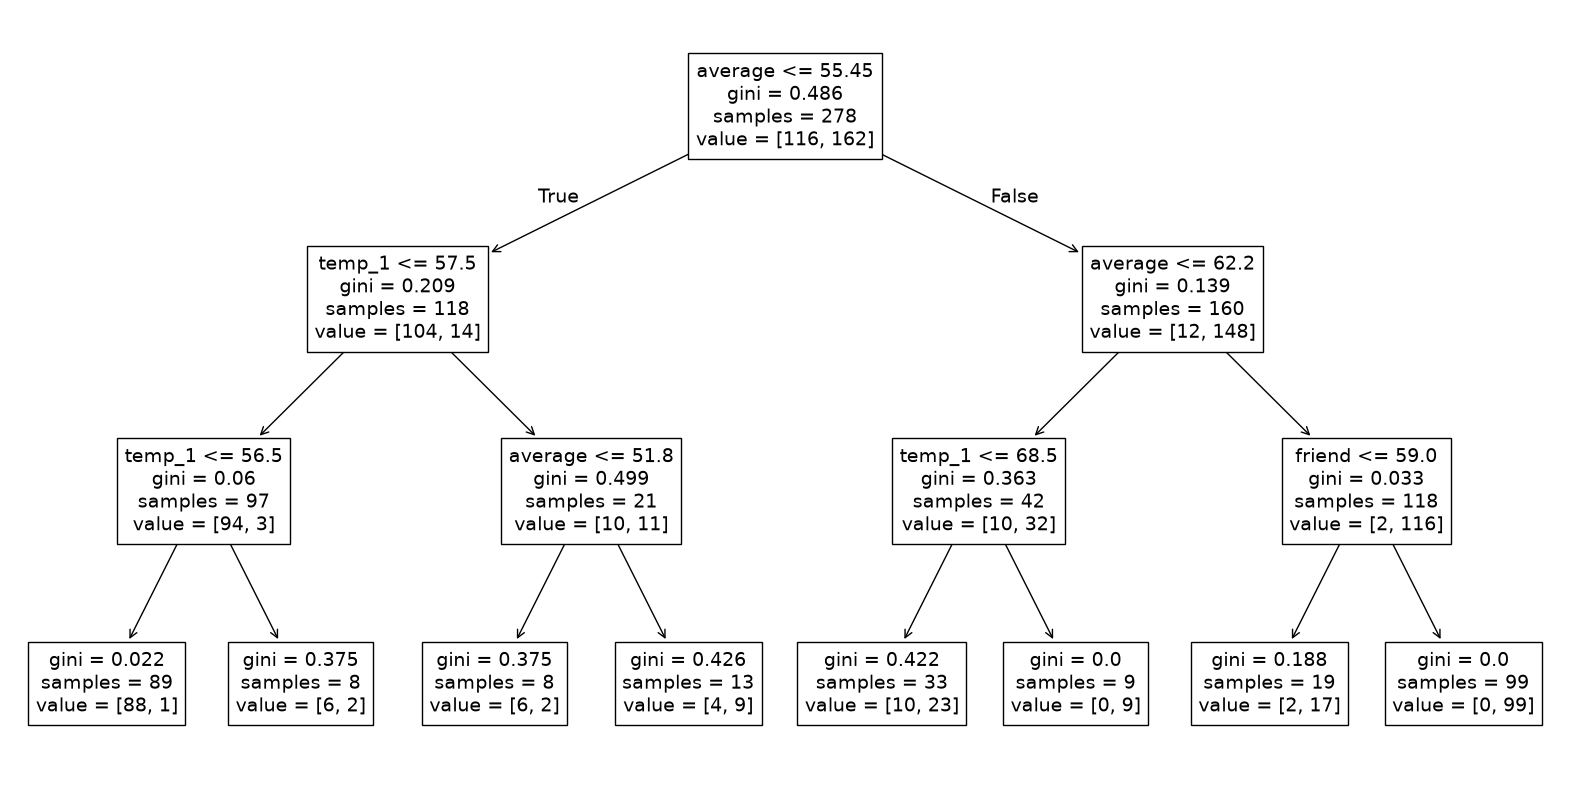

In [37]:
plt.figure(figsize=(20, 10))
plot_tree(mejor_modelo_clf, feature_names=X.columns)
plt.show()